In [6]:
import numpy as np
import os
import json
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.model_selection import KFold, cross_val_score

In [7]:
INPUT_FODLER = "wb_alif_clahe_collected_outputs_nano"

buf_fp32_scores = np.load(os.path.join(INPUT_FODLER, 'fp32_scores.npy'))
buf_fp32_boxes = np.load(os.path.join(INPUT_FODLER, 'fp32_boxes.npy'))
buf_uint8_scores = np.load(os.path.join(INPUT_FODLER, 'uint8_scores.npy'))
buf_uint8_boxes = np.load(os.path.join(INPUT_FODLER, 'uint8_boxes.npy'))

buf_fp32_scores.shape, buf_fp32_boxes.shape, buf_uint8_scores.shape, buf_uint8_boxes.shape

((12299, 1), (12299, 6), (12299, 1), (12299, 6))

(0.04599938, 0.056418043, 0.032286704, 0.86706215)

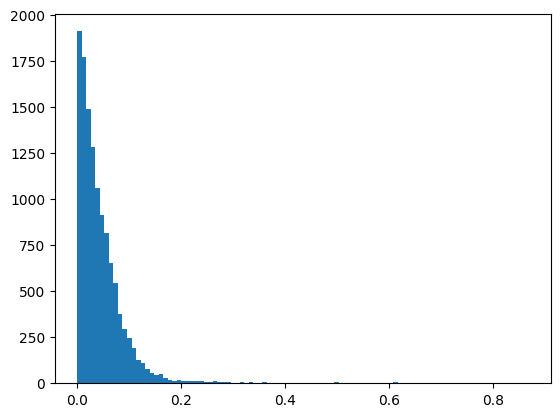

In [8]:
scores_dif = np.abs(buf_fp32_scores - buf_uint8_scores).flatten()
plt.hist(scores_dif, bins=100);
scores_dif.mean(), scores_dif.std(), np.median(scores_dif), scores_dif.max()

Coord dif mean: [6.798169  6.454886  9.135621  9.624807  4.7082577 4.7652144]
Coord dif std: [4.6928787 4.827376  6.9673467 6.946983  3.127714  3.114112 ]
Coord dif median: [5.995552  5.690075  7.5820923 8.23473   4.3621216 4.3910675]
Coord dif max: [18.117958 17.624458 39.77421  31.728498 15.137299 17.88034 ]


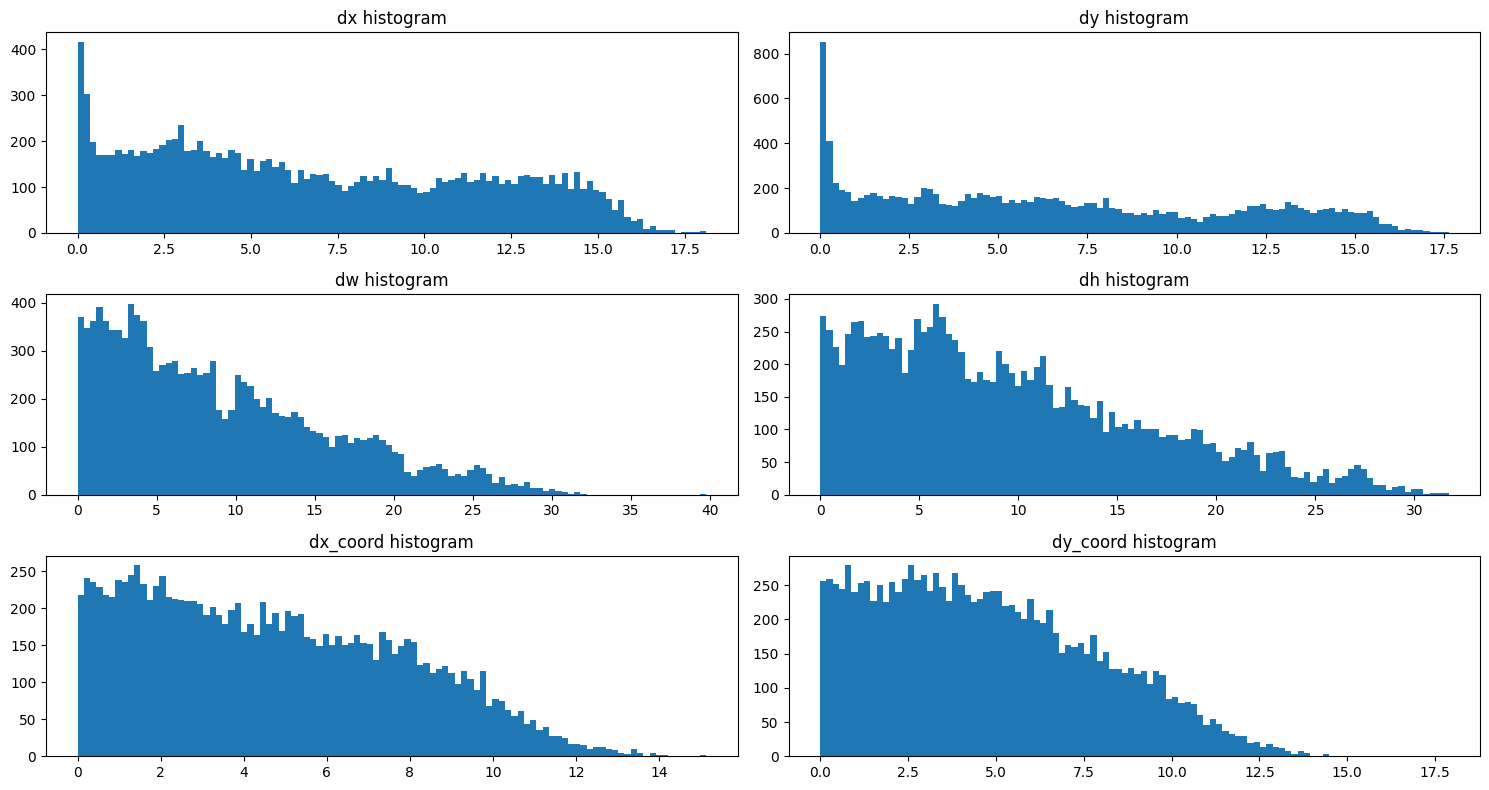

In [9]:
coord_dif = np.abs(buf_fp32_boxes - buf_uint8_boxes)
print("Coord dif mean:", coord_dif.mean(axis=0))
print("Coord dif std:", coord_dif.std(axis=0))
print("Coord dif median:", np.median(coord_dif, axis=0))
print("Coord dif max:", coord_dif.max(axis=0))

plt.figure(figsize=(15, 8))
plt.subplot(3, 2, 1)
plt.hist(coord_dif[:, 0].flatten(), bins=100)
plt.title('dx histogram')
plt.subplot(3, 2, 2)
plt.hist(coord_dif[:, 1].flatten(), bins=100)
plt.title('dy histogram')
plt.subplot(3, 2, 3)
plt.hist(coord_dif[:, 2].flatten(), bins=100)
plt.title('dw histogram')
plt.subplot(3, 2, 4)
plt.hist(coord_dif[:, 3].flatten(), bins=100)
plt.title('dh histogram')
plt.subplot(3, 2, 5)
plt.hist(coord_dif[:, 4].flatten(), bins=100)
plt.title('dx_coord histogram')
plt.subplot(3, 2, 6)
plt.hist(coord_dif[:, 5].flatten(), bins=100)
plt.title('dy_coord histogram')

plt.tight_layout()


In [10]:
# Train linear regression models for all 6 box coordinates
coord_names = ['dx', 'dy', 'dw', 'dh', 'dx_coord', 'dy_coord']
models = []

params = {}

# First: Train models on full dataset
for i in range(6):
    # X = buf_uint8_boxes[:, i].reshape(-1, 1)
    X = buf_uint8_boxes
    y = buf_fp32_boxes[:, i]
    
    # model = LinearRegression(fit_intercept=True)
    model = RidgeCV(fit_intercept=True, alphas=np.logspace(-2, 1, 50))
    model.fit(X, y)
    models.append(model)

    print(f"{coord_names[i]}:")
    print(f"  Coef: {model.coef_}, Intercept: {model.intercept_:.6f}, Alpha: {model.alpha_ if hasattr(model, 'alpha_') else 'N/A'}")
    params[coord_names[i]] = {
        'coef': [float(i) for i in model.coef_],
        'intercept': float(model.intercept_),
        'alpha': float(model.alpha_) if hasattr(model, 'alpha_') else None
    }

print("\n" + "="*50)
print("Model training completed\n")

# MSE comparison: FP32 vs UINT8 (without regression)
print("\n" + "="*50)
print("MSE: FP32 vs UINT8 (direct conversion)\n")
mse_uint8 = mean_squared_error(buf_fp32_boxes, buf_uint8_boxes, multioutput='raw_values')
for i, name in enumerate(coord_names):
    print(f"{name}: {mse_uint8[i]:.4f}")
print(f"Overall MSE: {mse_uint8.mean():.4f}")

# MSE comparison: FP32 vs Regression predictions (UINT8 as input)
print("\n" + "="*50)
print("MSE: FP32 vs Regression predictions (UINT8 input)\n")
predictions = np.column_stack([models[i].predict(buf_uint8_boxes) for i in range(6)])
mse_regression = mean_squared_error(buf_fp32_boxes, predictions, multioutput='raw_values')
for i, name in enumerate(coord_names):
    print(f"{name}: {mse_regression[i]:.4f}")
print(f"Overall MSE: {mse_regression.mean():.4f}")

# Improvement comparison
print("\n" + "="*50)
print("MSE Improvement (UINT8 -> Regression)\n")
for i, name in enumerate(coord_names):
    improvement = ((mse_uint8[i] - mse_regression[i]) / mse_uint8[i]) * 100
    print(f"{name}: {improvement:.2f}%")
print(f"Overall: {((mse_uint8.mean() - mse_regression.mean()) / mse_uint8.mean()) * 100:.2f}%")

file_name = 'wb_alif_clahe_ridge_regression_params_nano.json'
with open(file_name, 'w') as f:
    json.dump(params, f, indent=4)
print(f"\nRegression parameters saved to '{file_name}'")

dx:
  Coef: [ 0.83047466 -0.0223764   0.10797407 -0.02659397  0.20001449  0.02076373], Intercept: -16.021291, Alpha: 10.0
dy:
  Coef: [ 0.00260492  0.85885154 -0.02344411  0.12587046  0.00988255  0.16193558], Intercept: -14.779588, Alpha: 10.0
dw:
  Coef: [ 0.02404956  0.02936498  0.65069675  0.04881009 -0.03170708 -0.03169002], Intercept: 21.882324, Alpha: 10.0
dh:
  Coef: [ 0.02765368 -0.01153599  0.05900368  0.55865363 -0.05195602  0.00817426], Intercept: 26.118976, Alpha: 10.0
dx_coord:
  Coef: [ 0.16519792 -0.00881451  0.08126917 -0.01266136  0.79320349  0.00939546], Intercept: 7.597241, Alpha: 10.0
dy_coord:
  Coef: [ 0.00512331  0.18690566 -0.00113508  0.09578592 -0.00262923  0.77427967], Intercept: 4.669850, Alpha: 10.0

Model training completed


MSE: FP32 vs UINT8 (direct conversion)

dx: 68.2384
dy: 64.9693
dw: 132.0035
dh: 140.8972
dx_coord: 31.9503
dy_coord: 32.4051
Overall MSE: 78.4106

MSE: FP32 vs Regression predictions (UINT8 input)

dx: 48.6462
dy: 48.0304
dw: 83.2131